In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential,load_model
from tensorflow.keras.layers import Conv2D,MaxPooling2D, Flatten , Dense, Dropout,Input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
import splitfolders
import cv2
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers,models
import os
import random
import tensorboard 

2026-01-04 13:02:41.915648: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-04 13:02:42.011887: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-01-04 13:02:42.011943: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-01-04 13:02:42.014025: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-01-04 13:02:42.028014: I tensorflow/core/platform/cpu_feature_guar

In [2]:
input_dataset_path = '/home/maries/Development/Project_OWSLT/datasets/ASL Letters/'
output_result_path = '/home/maries/Development/Project_OWSLT/output/letter/output/'

#spliting the data for training , validation , testing 
split_ratio = (0.8 , 0.1 , 0.1)

splitfolders.ratio(
    input_dataset_path,
    output = output_result_path,
    seed   = 300,
    ratio  = split_ratio,
    group_prefix = None
)


Copying files: 9034 files [00:00, 19281.48 files/s]


In [3]:
input_dataset_path = '/home/maries/Development/Project_OWSLT/datasets/ASL Letters/'
output_result_path = '/home/maries/Development/Project_OWSLT/output/letter/output/'

In [4]:
#defining parameters
img_size = (224,224)
batch_size = 32

train_data_gen = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    rotation_range    = 10,
    width_shift_range = 0.2,
    height_shift_range= 0.2,
    shear_range       = 0.2,
    zoom_range        = 0.2,
    horizontal_flip   =True,
    fill_mode         ='nearest'
)



In [5]:
#Data aurgument for testing data (only rescaling)
test_data_gen = ImageDataGenerator(preprocessing_function = preprocess_input)
#Data arugument for validation data (only rescaling)
valid_data_gen= ImageDataGenerator(preprocessing_function = preprocess_input)

In [6]:
train_dir = os.path.join(output_result_path,'train')
val_dir   = os.path.join(output_result_path,'val')
test_dir   = os.path.join(output_result_path,'test')

train_data =  train_data_gen.flow_from_directory(
    train_dir,
    target_size = img_size,
    batch_size  = batch_size,
    class_mode  = 'categorical'
)

test_data = test_data_gen.flow_from_directory(
    test_dir,
    target_size =img_size,
    batch_size  = batch_size,
    class_mode  = 'categorical'
)

valid_data = valid_data_gen.flow_from_directory(
    val_dir,
    target_size = img_size,
    batch_size  = batch_size,
    class_mode  = 'categorical'
)

class_size = len(valid_data.class_indices)
class_labels = valid_data.class_indices


Found 7215 images belonging to 29 classes.
Found 927 images belonging to 29 classes.
Found 892 images belonging to 29 classes.


In [7]:
class_labels

{'A': 0,
 'B': 1,
 'C': 2,
 'D': 3,
 'E': 4,
 'F': 5,
 'G': 6,
 'H': 7,
 'I': 8,
 'J': 9,
 'K': 10,
 'L': 11,
 'M': 12,
 'N': 13,
 'O': 14,
 'P': 15,
 'Q': 16,
 'R': 17,
 'S': 18,
 'T': 19,
 'U': 20,
 'V': 21,
 'W': 22,
 'X': 23,
 'Y': 24,
 'Z': 25,
 'del': 26,
 'ok': 27,
 'space': 28}

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..151.061].


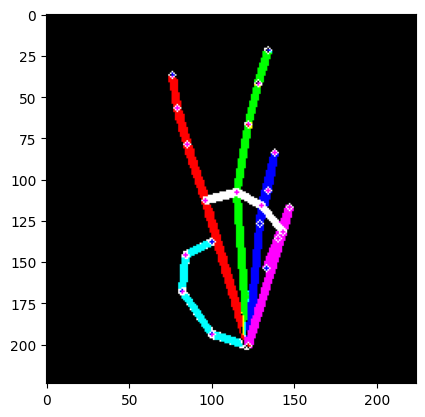

In [11]:
#get image from vaildation data
images, labels = next(valid_data)

#select a random image from the batch
idx = random.randint(0,len(images) -1)

#display the image
plt.imshow(images[idx])
plt.show()

In [12]:
from keras.applications.resnet import ResNet50
base_model = ResNet50(weights='imagenet', include_top = False , input_shape=( img_size[0], img_size[1] , 3 ))

#Freeze the convolutional base
base_model.trainable = False


2026-01-04 13:05:03.153805: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-01-04 13:05:03.205381: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-01-04 13:05:03.208756: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [13]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(class_size,activation='softmax'),
])

In [14]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d (  (None, 2048)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense (Dense)               (None, 512)               1049088   
                                                                 
 dropout (Dropout)           (None, 512)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               131328    
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                        

In [15]:

log_dir = '/home/maries/Development/Project_OWSLT/logs/'
tf_callback =  tf.keras.callbacks.TensorBoard(log_dir = log_dir)

In [16]:
model.compile(
    optimizer= 'adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:

model.fit(train_data ,epochs=50 ,validation_data= valid_data,callbacks=[tf_callback])

Epoch 1/50


2026-01-04 13:05:39.638970: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-01-04 13:05:43.808955: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f9e651a0e30 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-01-04 13:05:43.808973: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 2050, Compute Capability 8.6
2026-01-04 13:05:43.813189: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1767512143.866690   80689 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


226/226 [==============================] - 56s 217ms/step - loss: 2.5178 - accuracy: 0.2726 - val_loss: 0.7971 - val_accuracy: 0.8072
Epoch 2/50
226/226 [==============================] - 44s 193ms/step - loss: 1.0696 - accuracy: 0.6467 - val_loss: 0.2549 - val_accuracy: 0.9484
Epoch 3/50
226/226 [==============================] - 44s 192ms/step - loss: 0.6881 - accuracy: 0.7638 - val_loss: 0.0995 - val_accuracy: 0.9832
Epoch 4/50
226/226 [==============================] - 43s 192ms/step - loss: 0.5279 - accuracy: 0.8245 - val_loss: 0.0532 - val_accuracy: 0.9922
Epoch 5/50
226/226 [==============================] - 43s 192ms/step - loss: 0.4655 - accuracy: 0.8498 - val_loss: 0.0380 - val_accuracy: 0.9944
Epoch 6/50
226/226 [==============================] - 43s 192ms/step - loss: 0.3828 - accuracy: 0.8740 - val_loss: 0.0189 - val_accuracy: 0.9966
Epoch 7/50
226/226 [==============================] - 44s 192ms/step - loss: 0.3349 - accuracy: 0.8902 - val_loss: 0.0203 - val_accuracy: 0.9

KeyboardInterrupt: 

NameError: name 'history' is not defined

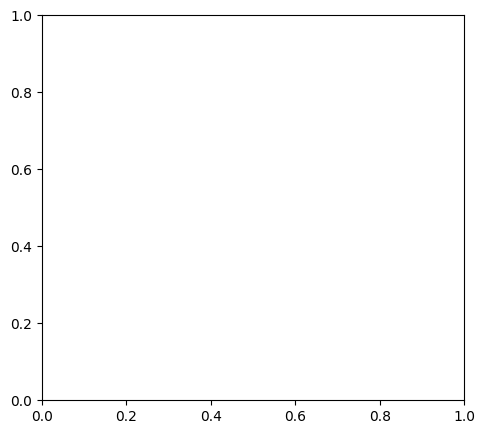

In [19]:

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['Train','Validation'],loc='upper left')

plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['Train','Validation'],loc='upper left')

plt.tight_layout()
plt.show()


In [18]:
#evaluate the model on the test data
test_loss, test_accuracy =model.evaluate(test_data)

print(f'Test Accuracy:{test_accuracy * 100:.2f}%')

29/29 [==============================] - 8s 276ms/step - loss: 0.0065 - accuracy: 0.9989
Test Accuracy:99.89%


In [15]:
class_names = {0:'0',
 1:'1',
 2:'2',
 3:'3',
 4:'4',
 5:'5',
 6:'6',
 7:'7',
 8:'8',
 9:'9',
 10:'del',
 11:'ok',
 12:'space'              
 }
class_names

{0: '0',
 1: '1',
 2: '2',
 3: '3',
 4: '4',
 5: '5',
 6: '6',
 7: '7',
 8: '8',
 9: '9',
 10: 'nothing'}

In [110]:

def predict_img(image,model):
    test_img = cv2.imread(image)
    test_img = cv2.resize(test_img,(224,224))
    test_img = np.expand_dims(test_img,axis=0)
    # test_img = cv2.cvtColor(test_img,cv2.COLOR_BGR2RGB)
    test_img_arr = preprocess_input(test_img)
    result = model.predict(test_img)
    r = np.argmax(result)
    print(class_names[r])

In [122]:
predict_img('/home/maries/Development/Project_OWSLT/test_in/out log/MOG/A9/1.jpg',model)

1/1 [==============================] - 0s 20ms/step
9


In [14]:
model.save('/home/maries/Development/Project_OWSLT/models/letter_modelV2.keras')

Model Summary

LSTM model

demo
